In [1]:
%load_ext autoreload
%autoreload 2
%matplotlib inline
import sys
import locale
import gc
from pathlib import Path

repo_root = Path.cwd().resolve()
for candidate in (repo_root, *repo_root.parents):
    if (candidate / 'otnse.py').exists() and (candidate / 'baseline').exists():
        repo_root = candidate
        break
else:
    raise FileNotFoundError('Could not locate project root containing otnse.py')
sys.path.append(str(repo_root))
sys.path.append(str(repo_root / 'baseline'))

import numpy as np
import pandas as pd
import scipy.signal
import scipy.ndimage
import scipy.stats
import scipy.spatial.distance
from scipy.io import loadmat
import matplotlib.pyplot as plt
from matplotlib import colors as mcolors
from otnse import otnse
from baselines import (
    UNIFORM_BASELINE_METHODS,
    pick_uniform_samples,
    interp_tf_map_to_time,
    run_stft_spectrogram,
    run_multitaper_spectrogram,
    run_music_spectrogram,
    run_wvd_spectrogram,
    run_spwvd_spectrogram,
    run_reassigned_spectrogram,
)
import warnings
import mne
# warnings.filterwarnings("ignore")
np.set_printoptions(precision=4, suppress=True)

from utils import LEGEND_FRAME, style_legend, bold_best_values, build_window_grid, compute_tf_metrics, dataset_repeat_seed, finish_nature_panel, format_otnse_q_params, nature_safe_name, normalize_tf_map, pick_obs, prepare_tf_display_map, run_index_assumed_uniform_baselines, run_s_transform, save_nature_colorbar, save_otnse_window_fit_psd, select_local_obs, set_utils, style_tf_ax, LOWER_IS_BETTER_METRICS


In [2]:
# Experiment presets
seed = 0
draw_otnse_window_figures = True
save_tf_figures =True
q_num = 3
print_q_params = True
tf_psd_scale = 'peak_normalized'  # structure comparison: each TF map is divided by its own full-map peak.
tf_db_eps = 1e-12

# Time-frequency figure display controls only affect plotted heatmaps; metrics still use the original maps.
tf_display_cmap = 'viridis'        # Perceptually uniform sequential map for PSD displays.
tf_error_cmap = 'magma'            # Sequential map for non-negative error displays.
tf_display_smooth_sigma = 1.0      # Gaussian smoothing in TF pixels; 0 disables smoothing.
tf_display_gamma = 0.8            # <1 brightens weak ridges for non-dB maps; 1 disables gamma correction.
tf_variance_display_vmin = 0.0
tf_variance_display_vmax = None
tf_rmse_display_vmin = 0.0
tf_rmse_display_vmax = None
trace_freqs = {
    'ssvep_sub02_15hz': (1, 15),  # 1 Hz background and the 15 Hz stimulus response.
    'ssvep_sub02_12hz': (1, 12),  # 1 Hz background and the 12 Hz stimulus response.
    'eegmat': (1.0, 7),
}
trace_colors = ('#00A8FF', '#FF2D2D')
trace_outline_color = '#FFFFFF'
# Figure typography controls. Adjust these values here instead of editing plotting cells.
tf_font = {'title': 25, 'label': 25, 'tick': 20, 'cbar_label': 15, 'cbar_tick': 15}
psd_trace_tf_font = {'title': 17, 'label': 17, 'tick': 16, 'cbar_label': 14, 'cbar_tick': 12}
metric_bar_font = {'label': 16, 'tick': 16, 'annotation': 12}
window_plot_font = {'label': 30, 'tick': 30, 'legend': 20}

# Apply window diagnostic plot fonts to the shared OTNSE window-plot style.
import otnse as otnse_module
otnse_module.WINDOW_PLOT_STYLE.update({
    'label_fontsize': window_plot_font['label'],
    'tick_fontsize': window_plot_font['tick'],
    'legend_fontsize': window_plot_font['legend'],
})


def trace_path_effects(linewidth):
    from matplotlib import patheffects as path_effects

    return [
        path_effects.Stroke(linewidth=linewidth + 2.0, foreground=trace_outline_color),
        path_effects.Normal(),
    ]


def draw_tf_trace_line(ax, frequency, color, linewidth=1.2, alpha=0.95):
    line = ax.axhline(frequency, color=color, linewidth=linewidth, alpha=alpha)
    line.set_path_effects(trace_path_effects(linewidth))
    return line
tf_panel_figsize = (3.6, 3.6)


def get_trace_freqs(ds):
    if ds not in trace_freqs:
        raise KeyError(f'No trace frequencies configured for {ds!r}.')
    freqs = np.asarray(trace_freqs[ds], dtype=np.float64).reshape(-1)
    if len(freqs) != 2:
        raise ValueError(f'{ds!r} must define exactly two frequency traces.')
    return freqs
max_resample_retries = 5
otnse_rmse_deviation_ratio = 0.15
otnse_retry_metric = 'RMSE'

# Method interface: edit tf_methods to decide which methods are computed, plotted, and scored.
tf_reference_method = 'S-Transform'
tf_methods = [
    'OTNSE',
    'ST (Incomplete)',
    'STFT',
    'Multitaper',
    'MUSIC',
    'SPWVD',
]
tf_supported_methods = {'OTNSE','OTNSE Uniform', 'YW', *UNIFORM_BASELINE_METHODS}
tf_selected_methods = list(dict.fromkeys(tf_methods))
unknown_tf_methods = [name for name in tf_selected_methods if name not in tf_supported_methods]
if unknown_tf_methods:
    raise ValueError(f'Unknown TF methods: {unknown_tf_methods}')
tf_uniform_baseline_methods = [name for name in tf_selected_methods if name in UNIFORM_BASELINE_METHODS]
tf_psd_plot_methods = [tf_reference_method] + tf_selected_methods
tf_method_labels = {
    'S-Transform': 'ST (Reference GT)',
}
tf_method_palette = {
    'OTNSE': '#2a6ebb',
    'OTNSE Uniform': '#00a6d6',
    'ST (Incomplete)': '#8FB8DE',
    'YW': '#f0ab00',
    'STFT': '#e03327',
    'MUSIC': '#1cd413',
    'Multitaper': '#c12bb4',
    'SPWVD': '#00a6a6',
    'Reassigned Spectrogram': '#6f8f00',
}
np.random.seed(seed)

# Select datasets here; each dataset reads its own settings from dataset_settings.


datasets=['ssvep_sub02_15hz','ssvep_sub02_12hz','eegmat']
#datasets = ['eegmat_subject31_run1']  # , 'brainstorm_raw'

n_repeats = 10
repeat_seeds = np.random.default_rng(seed).integers(1, np.iinfo(np.int32).max, size=n_repeats).tolist()
common_settings = {
    'sample_ratio': 1 / 6,
    'repeat_seeds': repeat_seeds,
    'hop_ratio': 0.25,
    'nfft_scale': 8,
    'multitaper_time_bandwidth': 2.0,
    'multitaper_tapers': 3,
    'st_sigma_scale': 1.0,
}

from dataset import get_dataset_configs  # dataset metadata lives in configs/dataset_configs.yaml
config_map = get_dataset_configs()

dataset_settings = {
    #Q=3

    # 'HR2': dict(common_settings, hr_file='hr2.txt', hr_sample_rate=2.0, sample_start=0, sample_stop=1800, sample_ratio=1 / 3, tf_window_seconds=150.0, freq_max=0.05, hop_ratio=0.25, nfft_scale=16, st_sigma_scale=1.2),

    #  'CPAP': dict(common_settings, cpap_subject=1, cpap_pressure='4cmH2O', cpap_breath_type='Normal', sample_start=1000, sample_stop=5000, sample_ratio=1 / 4, tf_window_seconds=8.0, freq_max=2, hop_ratio=0.25, nfft_scale=16, st_sigma_scale=1.2),
     
    'ssvep_sub02_15hz': dict(common_settings, channel='O2', epoch_tmin=-1.0, epoch_tmax=10.0, data_start_seconds=5, data_end_seconds=15.0, l_filter=0.5, h_filter=30.0, sample_ratio=1 / 3, tf_window_seconds=.5, freq_max=30.0, nfft_scale=16, st_sigma_scale=3),

    'eegmat': dict(common_settings, subject=1, run=2, channel='EEG Fz', chs=['EEG O2', 'EEG O1', 'EEG Pz', 'EEG Cz', 'EEG C3', 'EEG C4'], data_start_seconds=28.0, data_end_seconds=38, l_filter=0.5, h_filter=40.0, notch=50.0, sample_ratio=1 / 3, tf_window_seconds=1, freq_max=20.0, hop_ratio=0.25,nfft_scale=16, st_sigma_scale=3.0),

    'eegbci_motor_sub04': dict(common_settings, subject=4, run=2, channel='O1', data_start_seconds=0.0, data_end_seconds=20.0, l_filter=30, h_filter=40.0, sample_ratio=1 / 6, tf_window_seconds=2.0, freq_max=20.0, nfft_scale=8, st_sigma_scale=3.0, max_freq_points=512),

    'eegbci_motor_sub01': dict(common_settings, subject=21, run=2, channel='O2', data_start_seconds=20.0, data_end_seconds=30.0, l_filter=0.5, h_filter=40.0, sample_ratio=1 / 6, tf_window_seconds=2.0, freq_max=20.0, nfft_scale=8, st_sigma_scale=3.0, max_freq_points=512),

     'ssvep_sub02_12hz': dict(common_settings, channel='O2', epoch_tmin=-1.0, epoch_tmax=10.0, data_start_seconds=5, data_end_seconds=15.0, l_filter=0.5, h_filter=30.0, sample_ratio=1 / 3, tf_window_seconds=.5, freq_max=30.0, nfft_scale=16, st_sigma_scale=2.5),
    
#     'auditoryeeg': dict(common_settings, subject=5, experiment=2, session=1, 
#     record=None, channel='P4', chs=['Cz', 'P4', 'F8', 'T7'], data_start_seconds=30.0, data_end_seconds=40.0, l_filter=1.0, h_filter=30.0, notch=50.0, sample_ratio=1 / 3, tf_window_seconds=2.0, freq_max=30.0, nfft_scale=16, st_sigma_scale=1.0,hop_ratio=0.25),

#     'mitbih_100': dict(common_settings, mitbih_record='100', mitbih_channel='MLII', sample_start=0, sample_stop=3600, sample_ratio=1 / 3, tf_window_seconds=1.0, freq_max=40.0, nfft_scale=16, st_sigma_scale=1.0),


    'bciciv_a03t': dict(common_settings, file='A03E.gdf', channel='C3', data_start_seconds=5.0, data_end_seconds=10.0, l_filter=0.5, h_filter=30.0, notch=50.0, chs=['EEG-C3', 'C3', 'EEG-Cz', 'Cz', 'EEG-C4', 'C4'], sample_ratio=1 / 3, tf_window_seconds=1.0, freq_max=20.0, nfft_scale=16, st_sigma_scale=3.0, max_freq_points=512),

    'chbmit_chb01': dict(common_settings, subject=2, run=3, channel='FP2-F4', data_start_seconds=12, data_end_seconds=30, l_filter=0.5, h_filter=30.0, notch=60.0, sample_ratio=1 / 3, tf_window_seconds=1.5, freq_max=10.0, nfft_scale=16, st_sigma_scale=1.0)

    #'chbmit_chb01': dict(common_settings, subject=2, run=3, channel='FP2-F4', data_start_seconds=12, data_end_seconds=18, l_filter=0.5, h_filter=30.0, notch=60.0, sample_ratio=1 / 3, tf_window_seconds=0.75, freq_max=10.0, nfft_scale=16, st_sigma_scale=1.0)

#     'mamem_u001ai': dict(common_settings, file='U001ai.mat', channel='Oz', chs=['O2', 'O1', 'Oz', 'POz', 'PO3', 'PO4', 'Pz'], data_start_seconds=20.0, data_end_seconds=30.0, sample_ratio=1 / 3, tf_window_seconds=1.0, freq_max=20.0, nfft_scale=16, st_sigma_scale=1.0),

#     'dreams_patient6': dict(common_settings, patient=6, channel='O2-A1', chs=['O2-A1', 'O1-A2', 'CZ-A1', 'FP1-A2', 'FP2-A1'], data_start_seconds=20.0, data_end_seconds=40.0, l_filter=0.5, h_filter=40.0, notch=50.0, sample_ratio=1 / 3, tf_window_seconds=3.0, freq_max=40.0, nfft_scale=16, st_sigma_scale=3.0),

#     'brainstorm_raw': dict(common_settings, subject='subj001', data_start_seconds=0.0, data_end_seconds=7.0, l_filter=0.5, h_filter=20.0, sample_ratio=1 / 6, tf_window_seconds=1.5, freq_max=20.0, nfft_scale=32, st_sigma_scale=1.0),

#     # 'chbmit_chb01': dict(common_settings, subject=2, run=3, channel='FP2-F4', data_start_seconds=32, data_end_seconds=40, l_filter=0.5, h_filter=100.0, notch=60.0, sample_ratio=1 / 3, tf_window_seconds=0.5, freq_max=10.0, nfft_scale=16, st_sigma_scale=1.0),
# }
}

fig_dir = repo_root / 'figures' / 'tf_main_multiq'
save_format = 'pdf'
cmap = tf_display_cmap
error_cmap = tf_error_cmap
ssim_window_size = 7
comparison_figsize = (3.6, 3.6)
rmse_figsize = (7.2, 4.8)

plot_params = {'legend.fontsize': 16,
               'figure.figsize': (7.2, 4.8),
               'xtick.labelsize': '8',
               'ytick.labelsize': '8',
               'axes.titlesize': '10',
               'axes.labelsize': '10',
               'font.family': 'sans-serif',
               'font.sans-serif': ['Arial', 'Helvetica', 'DejaVu Sans'],
               'font.weight': 'normal',
               'axes.titleweight': 'normal',
               'axes.labelweight': 'normal',
               'axes.linewidth': 0.8,
               'pdf.fonttype': 42,
               'svg.fonttype': 'none'}
plt.rcParams.update(plot_params)
nature_panel_dpi = 300
nature_show_panels = False
set_utils(seed=seed, tf_psd_scale=tf_psd_scale, tf_db_eps=tf_db_eps, tf_display_smooth_sigma=tf_display_smooth_sigma, tf_display_gamma=tf_display_gamma, nature_panel_dpi=nature_panel_dpi, nature_show_panels=nature_show_panels, plot_params=plot_params, ssim_window_size=ssim_window_size, cmap=cmap, tf_font=tf_font, draw_otnse_window_figures=draw_otnse_window_figures)


In [3]:
from dataset import load_dataset, overlay_synthetic_true_freq_tracks, set_loader

set_loader(
    seed=seed,
    repo_root=repo_root,
    config_map=config_map,
)


In [4]:

def resample_seed(base_seed, attempt_idx):
    return int(base_seed) + 1000 * int(attempt_idx)

def is_retryable_error(err):
    if isinstance(err, np.linalg.LinAlgError):
        return True
    if isinstance(err, FloatingPointError):
        return True
    if isinstance(err, ValueError) and 'fewer than 2 observations' in str(err):
        return True
    return False

def clear_cache(*names):
    for name in names:
        globals().pop(name, None)
    gc.collect()



In [5]:


def estimate_ar_psd(signal, sample_rate, freq_grid, max_order=10):
    signal = np.asarray(signal, dtype=np.float64)
    freq_grid = np.asarray(freq_grid, dtype=np.float64)
    n = len(signal)
    if n < 4 or np.std(signal) <= 0 or sample_rate <= 0:
        return np.zeros(len(freq_grid), dtype=np.float32)
    y = signal - np.mean(signal)
    order = int(min(max_order, n - 2))
    autocov = np.asarray([np.dot(y[:n - lag], y[lag:]) / float(n) for lag in range(order + 1)], dtype=np.float64)
    if not np.isfinite(autocov[0]) or autocov[0] <= 0:
        return np.zeros(len(freq_grid), dtype=np.float32)
    idx = np.arange(order)
    toeplitz = autocov[np.abs(idx[:, None] - idx[None, :])]
    rhs = -autocov[1:order + 1]
    ridge = max(1e-10, 1e-08 * float(autocov[0]))
    try:
        ar_coeff = np.linalg.solve(toeplitz + ridge * np.eye(order), rhs)
    except np.linalg.LinAlgError:
        ar_coeff = np.linalg.lstsq(toeplitz + ridge * np.eye(order), rhs, rcond=None)[0]
    noise_var = float(autocov[0] + np.dot(ar_coeff, autocov[1:order + 1]))
    noise_var = max(noise_var, np.finfo(float).tiny)
    valid = (freq_grid >= 0) & (freq_grid <= 0.5 * float(sample_rate))
    psd = np.zeros(len(freq_grid), dtype=np.float64)
    if np.any(valid):
        omega = 2.0 * np.pi * freq_grid[valid] / float(sample_rate)
        powers = np.arange(order + 1, dtype=np.float64)
        coeff = np.concatenate(([1.0], ar_coeff))
        denom = np.abs(np.exp(-1j * omega[:, None] * powers[None, :]) @ coeff) ** 2
        psd[valid] = noise_var / (float(sample_rate) * np.maximum(denom, np.finfo(float).tiny))
    return psd.astype(np.float32)

def run_sliding_ar(obs_time, obs_signal, window_lefts, window_rights, time_centers, freq_grid, max_order=10):
    ar_psd = np.zeros((len(time_centers), len(freq_grid)), dtype=np.float32)
    for row, tau in enumerate(time_centers):
        window_left = float(window_lefts[row])
        window_right = float(window_rights[row])
        local_time, local_signal = select_local_obs(obs_time=obs_time, obs_signal=obs_signal, window_left=window_left, window_right=window_right)
        if len(local_time) < 4 or np.std(local_signal) <= 0:
            continue
        local_dt = float(np.median(np.diff(local_time)))
        local_fs = 1.0 / local_dt if np.isfinite(local_dt) and local_dt > 0 else np.nan
        if not np.isfinite(local_fs) or local_fs <= 0:
            continue
        ar_psd[row] = estimate_ar_psd(local_signal, local_fs, freq_grid, max_order=max_order)
    return ar_psd



In [6]:

def run_otnse_tf_map(
    obs_time,
    obs_signal,
    fit_time,
    fgrid,
    win_l,
    win_r,
    win_s,
    b,
    spec,
    display_min,
    reference_map,
    window_plot_root=None,
    repeat_idx=None,
    attempt_idx=None,
    require_min_local_obs=False,
    draw_window_plots=False,
    log_label=None,
):
    psd_rows = []
    psd_std_rows = []
    real_rows = []
    imag_rows = []
    train_times = []
    local_obs_counts = []
    prev_params = None
    otnse_freq = None

    for window_idx, tau in enumerate(fit_time):
        window_left = float(win_l[window_idx])
        window_right = float(win_r[window_idx])
        local_time, local_signal = select_local_obs(
            obs_time=obs_time,
            obs_signal=obs_signal,
            window_left=window_left,
            window_right=window_right,
        )
        if require_min_local_obs and len(local_time) < 2:
            raise ValueError(f'window {window_idx} has fewer than 2 observations without padding')
                # Unified experiment semantics: angular-frequency training
        # (Hz LS init and Hz output/plotting kept; optimization in angular space).
        model = otnse(local_time, local_signal, float(tau), win_s, q=q_num, optimizer='angular')
        model.set_labels(spec['time_label'], spec['signal_label'])
        model.w = fgrid.copy()
        if prev_params is not None:
            model.set_params(prev_params, float(tau), float(b))
        else:
            model.compute_moments()
        _, train_time = model.train()
        prev_params = model.params()
        if print_q_params:
            label = 'OTNSE' if log_label is None else str(log_label)
            print(f"{label} window {window_idx + 1}/{len(fit_time)} tau={float(tau):.6g}: {format_otnse_q_params(prev_params)}")
        model.compute_moments()
        otnse_freq, mean_psd, var_psd = model.return_psd(return_variance=True)
        std_psd = np.sqrt(np.clip(var_psd, 0.0, None))
        post_mean_r = np.asarray(model.post_mean_r, dtype=np.float32)
        post_mean_i = np.asarray(model.post_mean_i, dtype=np.float32)
        if draw_window_plots and window_plot_root is not None:
            repeat_dir = f'repeat_{repeat_idx}'
            if attempt_idx is not None:
                repeat_dir = f'{repeat_dir}_attempt_{attempt_idx}'
            save_otnse_window_fit_psd(
                model=model,
                output_dir=window_plot_root / repeat_dir / f'window_{window_idx}',
                window_index=window_idx,
                all_obs_time=obs_time,
                all_obs_signal=obs_signal,
                window_left=window_left,
                window_right=window_right,
                time_label=spec['time_label'],
                signal_label=spec['signal_label'],
            )

        psd_rows.append(np.asarray(mean_psd, dtype=np.float32))
        psd_std_rows.append(np.asarray(std_psd, dtype=np.float32))
        real_rows.append(post_mean_r)
        imag_rows.append(post_mean_i)
        train_times.append(float(train_time))
        local_obs_counts.append(int(len(local_time)))

    otnse_psd = np.stack(psd_rows)
    otnse_psd_std = np.stack(psd_std_rows)
    otnse_real = np.stack(real_rows)
    otnse_imag = np.stack(imag_rows)
    otnse_map = normalize_tf_map(otnse_psd, display_min)
    std_scale_mode = 'absolute' if tf_psd_scale == 'db' else tf_psd_scale
    otnse_std_map = normalize_tf_map(otnse_psd_std, display_min, scale_mode=std_scale_mode)
    diff_map = otnse_map - reference_map
    metrics = compute_tf_metrics(reference_map, otnse_map, display_min, fit_time, fgrid)

    local_obs_min = int(np.min(local_obs_counts)) if local_obs_counts else 0
    local_obs_max = int(np.max(local_obs_counts)) if local_obs_counts else 0
    return {
        'raw_psd': np.asarray(otnse_psd, dtype=np.float32),
        'raw_psd_std': np.asarray(otnse_psd_std, dtype=np.float32),
        'map': otnse_map,
        'std_map': otnse_std_map,
        'diff_map': diff_map,
        'real_map': otnse_real,
        'imag_map': otnse_imag,
        'metrics': metrics,
        'freq': otnse_freq,
        'train_time_total': float(np.sum(train_times)) if train_times else np.nan,
        'local_obs_mean': float(np.mean(local_obs_counts)) if local_obs_counts else np.nan,
        'local_obs_min': local_obs_min,
        'local_obs_max': local_obs_max,
    }


rep_rows = []
meth_rows = []
failure_rows = []
tf_plot_cache = {}
selected_methods = tf_selected_methods
uniform_baseline_methods = tf_uniform_baseline_methods
run_otnse = 'OTNSE' in selected_methods
run_uniform_otnse = 'OTNSE Uniform' in selected_methods
use_sliding_ar = 'YW' in selected_methods

for ds in datasets:
    cfg = dataset_settings[ds]
    signal, time, spec = load_dataset(ds, cfg)
    fs = float(spec['sfreq'])
    win_s = float(cfg['tf_window_seconds'])

    nperseg = int(round(win_s * fs))
    nperseg = int(np.clip(nperseg, 2, len(signal)))
    hop = max(1, int(round(nperseg * cfg['hop_ratio'])))
    noverlap = max(0, nperseg - hop)
    nfft = max(nperseg, 1 << (int(nperseg * cfg['nfft_scale']) - 1).bit_length())
    _, _, window_starts, window_stops, fit_time = build_window_grid(time, fs, win_s, cfg['hop_ratio'])
    stft_freq, _, _ = scipy.signal.spectrogram(
        signal - np.mean(signal),
        fs=fs,
        window='hann',
        nperseg=nperseg,
        noverlap=noverlap,
        nfft=nfft,
        detrend='constant',
        scaling='density',
        mode='psd',
    )
    fit_time = fit_time.astype(np.float32)
    stft_freq = stft_freq.astype(np.float32)

    stft_eval_mask = (stft_freq >= 0) & (stft_freq <= spec['freq_max'])
    freq = stft_freq[stft_eval_mask]
    max_freq_points = cfg.get('max_freq_points')
    if max_freq_points is not None and len(freq) > int(max_freq_points):
        freq_idx = np.linspace(0, len(freq) - 1, int(max_freq_points), dtype=np.int32)
        freq = freq[freq_idx]
        print(f"downsample TF frequency grid to {len(freq)} points for training speed")
    s_transform_gt = run_s_transform(signal, time, fit_time, freq, fs, sigma_scale=cfg['st_sigma_scale'])
    display_min = 0.0
    s_transform_gt_norm = normalize_tf_map(s_transform_gt, display_min)

    index_baseline_stacks = {name: [] for name in uniform_baseline_methods}

    duration = float(time[-1] - time[0])
    unit = 's' if spec['time_label'] == 'Time (s)' else spec['time_label']
    print()
    print(f'=== {ds} ===')
    print(f"signal label: {spec['signal_label']}")
    print(f"samples: {len(signal)}, duration: {duration:.3f} {unit}, fs: {fs:.3f} Hz")
    print(f"target freq max: {spec['freq_max']} Hz, aligned freq max: {float(freq[-1]):.6f} Hz")
    print(f"stft window: {nperseg / fs:.3f} s, hop: {hop / fs:.3f} s, nperseg: {nperseg}, nfft: {nfft}")
    print(f"S-transform sigma scale: {cfg['st_sigma_scale']}")
    print(f"sample ratio: {cfg['sample_ratio']:.3f}, repeats: {cfg['repeat_seeds']}")
    print(f"multitaper: NW={cfg['multitaper_time_bandwidth']}, tapers={cfg['multitaper_tapers']}")
    print(f"Ground truth: {tf_reference_method}")
    print('Selected methods: ' + ', '.join(selected_methods))
    if uniform_baseline_methods:
        print('Index-assumed uniform baselines: ' + ', '.join(uniform_baseline_methods))
    print(f"configured tf window: {win_s:.3f} s, PSD scale: {tf_psd_scale}")
    if tf_psd_scale == 'db':
        print("display reference: 10*log10(PSD), no peak normalization; metrics computed on dB maps")
    elif tf_psd_scale == 'absolute':
        print("display reference: absolute PSD amplitude, common robust color scale across methods")
    else:
        print("display reference: each method is linearly normalized by its own full-map peak PSD")
    if spec['kind'] in ('edf', 'chbmit', 'ssvep'):
        print(f"data segment: start {cfg['data_start_seconds']:.3f} s, end {cfg['data_end_seconds']:.3f} s")
    print(f"adaptive window count: {len(fit_time)}, window: {win_s:.3f} s, hop: {hop / fs:.3f} s")
    print('otnse local window: exact fixed slice, no padding or retry fill')

    available_tf_maps = {tf_reference_method: s_transform_gt_norm}
    otnse_psd_mean = None
    otnse_psd_std_mean = None
    real_mean = None
    imag_mean = None
    b = win_s / np.sqrt(2.0)
    window_lefts = time[window_starts].astype(np.float64)
    window_rights = time[window_stops - 1].astype(np.float64)
    fgrid = freq.astype(np.float64, copy=True)
    window_plot_root = fig_dir / str(ds).replace(' ', '_').replace('/', '_') / 'otnse_windows'

    if run_otnse:
        ot_stack = []
        raw_psd_stack = []
        raw_psd_std_stack = []
        real_stack = []
        imag_stack = []
        first_repeat_real = None
        first_repeat_imag = None
        otnse_rmse_baseline = None
        for repeat_idx, repeat_seed in enumerate(cfg['repeat_seeds'], start=1):
            base_sample_seed = dataset_repeat_seed(ds, repeat_seed)
            attempted_seeds = []
            last_rmse = np.nan
            last_threshold = np.nan
            last_reject_reason = ''
            last_error_type = ''
            last_error_message = ''
            for attempt_idx in range(max_resample_retries + 1):
                attempt_seed = resample_seed(base_sample_seed, attempt_idx)
                attempted_seeds.append(attempt_seed)
                try:
                    obs_time, obs_signal = pick_obs(signal, time, ratio=cfg['sample_ratio'], random_seed=attempt_seed)
                    otnse_result = run_otnse_tf_map(
                        obs_time=obs_time,
                        obs_signal=obs_signal,
                        fit_time=fit_time,
                        fgrid=fgrid,
                        win_l=window_lefts,
                        win_r=window_rights,
                        win_s=win_s,
                        b=b,
                        spec=spec,
                        display_min=display_min,
                        reference_map=s_transform_gt_norm,
                        window_plot_root=window_plot_root,
                        repeat_idx=repeat_idx,
                        attempt_idx=attempt_idx,
                        require_min_local_obs=True,
                        draw_window_plots=draw_otnse_window_figures and repeat_idx == 1,
                        log_label=f'{ds} repeat {repeat_idx} attempt {attempt_idx}',
                    )
                    metrics = otnse_result['metrics']
                    retry_value = float(metrics.get(otnse_retry_metric, np.nan))
                    last_rmse = float(metrics.get('RMSE', np.nan))
                    last_threshold = (
                        np.nan if otnse_rmse_baseline is None
                        else float(otnse_rmse_baseline) * (1.0 + float(otnse_rmse_deviation_ratio))
                    )
                    if not np.isfinite(retry_value):
                        last_reject_reason = f'{otnse_retry_metric} is not finite'
                        last_error_type = 'NonFiniteMetric'
                        last_error_message = last_reject_reason
                    elif otnse_rmse_baseline is not None and retry_value > last_threshold:
                        last_reject_reason = f'{otnse_retry_metric} {retry_value:.6g} exceeds baseline threshold {last_threshold:.6g}'
                        last_error_type = 'MetricThreshold'
                        last_error_message = last_reject_reason
                    else:
                        last_reject_reason = ''
                        last_error_type = ''
                        last_error_message = ''
                except (np.linalg.LinAlgError, FloatingPointError, ValueError) as err:
                    if not is_retryable_error(err):
                        raise
                    last_reject_reason = f'{type(err).__name__}: {err}'
                    last_error_type = type(err).__name__
                    last_error_message = str(err)
                    clear_cache('otnse_result', 'obs_time', 'obs_signal', 'metrics')
                    if attempt_idx < max_resample_retries:
                        print(f"retry {attempt_idx + 1}/{max_resample_retries}: {ds} repeat={repeat_idx} seed={attempt_seed} error={type(err).__name__}: {err}")
                        continue
                    failure_rows.append({
                        'Dataset': ds,
                        'Method': 'OTNSE',
                        'Repeat': repeat_idx,
                        'Base Seed': repeat_seed,
                        'Attempted Seeds': attempted_seeds.copy(),
                        'Attempts Used': len(attempted_seeds),
                        'RMSE Baseline': otnse_rmse_baseline,
                        'RMSE Threshold': last_threshold,
                        'Last RMSE': last_rmse,
                        'Reject Reason': last_reject_reason,
                        'Error Type': last_error_type,
                        'Error Message': last_error_message,
                    })
                    print(f"skip repeat after {len(attempted_seeds)} attempts: {ds} repeat={repeat_idx} error={type(err).__name__}: {err}")
                    break

                if last_reject_reason:
                    clear_cache('otnse_result', 'obs_time', 'obs_signal', 'metrics')
                    if attempt_idx < max_resample_retries:
                        print(f"retry {attempt_idx + 1}/{max_resample_retries}: {ds} repeat={repeat_idx} seed={attempt_seed} reason={last_reject_reason}")
                        continue
                    failure_rows.append({
                        'Dataset': ds,
                        'Method': 'OTNSE',
                        'Repeat': repeat_idx,
                        'Base Seed': repeat_seed,
                        'Attempted Seeds': attempted_seeds.copy(),
                        'Attempts Used': len(attempted_seeds),
                        'RMSE Baseline': otnse_rmse_baseline,
                        'RMSE Threshold': last_threshold,
                        'Last RMSE': last_rmse,
                        'Reject Reason': last_reject_reason,
                        'Error Type': last_error_type,
                        'Error Message': last_error_message,
                    })
                    print(f"skip repeat after {len(attempted_seeds)} attempts: {ds} repeat={repeat_idx} reason={last_reject_reason}")
                    break

                if otnse_rmse_baseline is None:
                    otnse_rmse_baseline = retry_value
                rmse_baseline = float(otnse_rmse_baseline)
                rmse_threshold = rmse_baseline * (1.0 + float(otnse_rmse_deviation_ratio))
                train_time_total = otnse_result['train_time_total']
                local_obs_mean = otnse_result['local_obs_mean']
                local_obs_min = otnse_result['local_obs_min']
                local_obs_max = otnse_result['local_obs_max']

                ot_stack.append(otnse_result['map'])
                raw_psd_stack.append(otnse_result['raw_psd'])
                raw_psd_std_stack.append(otnse_result['raw_psd_std'])
                real_stack.append(otnse_result['real_map'])
                imag_stack.append(otnse_result['imag_map'])
                if repeat_idx == 1:
                    first_repeat_real = otnse_result['real_map'].copy()
                    first_repeat_imag = otnse_result['imag_map'].copy()
                rep_rows.append({
                    'Dataset': ds,
                    'Repeat': repeat_idx,
                    'Seed': attempt_seed,
                    'Base Seed': repeat_seed,
                    'Resample Attempt': attempt_idx,
                    'RMSE Baseline': rmse_baseline,
                    'RMSE Threshold': rmse_threshold,
                    'Reject Reason': '',
                    'Time Centers': len(fit_time),
                    'Freq Points': len(otnse_result['freq']),
                    'Train Total (s)': train_time_total,
                    'Local Obs Mean': local_obs_mean,
                    'Local Obs Min': local_obs_min,
                    'Local Obs Max': local_obs_max,
                    **metrics,
                })
                meth_rows.append({
                    'Dataset': ds,
                    'Method': 'OTNSE',
                    'Repeat': repeat_idx,
                    'Seed': attempt_seed,
                    'Base Seed': repeat_seed,
                    'Resample Attempt': attempt_idx,
                    'RMSE Baseline': rmse_baseline,
                    'RMSE Threshold': rmse_threshold,
                    'Reject Reason': '',
                    **metrics,
                })
                if uniform_baseline_methods:
                    index_baseline_psd, index_baseline_meta = run_index_assumed_uniform_baselines(
                        obs_signal=obs_signal,
                        source_time=time,
                        target_time=fit_time,
                        target_freq=freq,
                        window_seconds=win_s,
                        hop_ratio=cfg['hop_ratio'],
                        nfft_scale=cfg['nfft_scale'],
                        time_bandwidth=cfg['multitaper_time_bandwidth'],
                        tapers_count=cfg['multitaper_tapers'],
                        sigma_scale=cfg['st_sigma_scale'],
                        methods=uniform_baseline_methods,
                    )
                    for method_name, method_psd in index_baseline_psd.items():
                        method_map = normalize_tf_map(method_psd, display_min)
                        index_baseline_stacks[method_name].append(method_map)
                        method_metrics = compute_tf_metrics(s_transform_gt_norm, method_map, display_min, fit_time, freq)
                        meth_rows.append({
                            'Dataset': ds,
                            'Method': method_name,
                            'Repeat': repeat_idx,
                            'Seed': attempt_seed,
                            'Base Seed': repeat_seed,
                            'Resample Attempt': attempt_idx,
                            **index_baseline_meta,
                            **method_metrics,
                        })
                retry_note = f", resampled seed={attempt_seed}, attempt={attempt_idx}" if attempt_idx else ""
                print(
                    f"repeat {repeat_idx}/{len(cfg['repeat_seeds'])} seed={repeat_seed}, sample_seed={base_sample_seed}{retry_note}: "
                    f"train total {train_time_total:.3f} s, local obs mean {local_obs_mean:.1f}, min {local_obs_min}, max {local_obs_max}, "
                    f"{otnse_retry_metric}={retry_value:.4f}, baseline={rmse_baseline:.4f}, threshold={rmse_threshold:.4f}"
                )
                break

        if ot_stack:
            available_tf_maps['OTNSE'] = np.mean(np.stack(ot_stack), axis=0)
            otnse_psd_mean = np.mean(np.stack(raw_psd_stack), axis=0)
            otnse_psd_std_mean = np.mean(np.stack(raw_psd_std_stack), axis=0)
            real_mean = np.mean(np.stack(real_stack), axis=0)
            imag_mean = np.mean(np.stack(imag_stack), axis=0)
        else:
            print(f"no successful OTNSE repeats for {ds}; skip OTNSE TF map")
        for method_name, method_stack in index_baseline_stacks.items():
            if method_stack:
                available_tf_maps[method_name] = np.mean(np.stack(method_stack), axis=0)
            else:
                print(f"no successful index-assumed baseline repeats for {ds} {method_name}; skip TF map")

    elif uniform_baseline_methods:
        for repeat_idx, repeat_seed in enumerate(cfg['repeat_seeds'], start=1):
            attempt_seed = dataset_repeat_seed(ds, repeat_seed)
            obs_time, obs_signal = pick_obs(signal, time, ratio=cfg['sample_ratio'], random_seed=attempt_seed)
            index_baseline_psd, index_baseline_meta = run_index_assumed_uniform_baselines(
                obs_signal=obs_signal,
                source_time=time,
                target_time=fit_time,
                target_freq=freq,
                window_seconds=win_s,
                hop_ratio=cfg['hop_ratio'],
                nfft_scale=cfg['nfft_scale'],
                time_bandwidth=cfg['multitaper_time_bandwidth'],
                tapers_count=cfg['multitaper_tapers'],
                sigma_scale=cfg['st_sigma_scale'],
                methods=uniform_baseline_methods,
            )
            for method_name, method_psd in index_baseline_psd.items():
                method_map = normalize_tf_map(method_psd, display_min)
                index_baseline_stacks[method_name].append(method_map)
                method_metrics = compute_tf_metrics(s_transform_gt_norm, method_map, display_min, fit_time, freq)
                meth_rows.append({
                    'Dataset': ds,
                    'Method': method_name,
                    'Repeat': repeat_idx,
                    'Seed': attempt_seed,
                    'Base Seed': repeat_seed,
                    'Resample Attempt': 0,
                    **index_baseline_meta,
                    **method_metrics,
                })
        for method_name, method_stack in index_baseline_stacks.items():
            if method_stack:
                available_tf_maps[method_name] = np.mean(np.stack(method_stack), axis=0)
            else:
                print(f"no successful index-assumed baseline repeats for {ds} {method_name}; skip TF map")

    if use_sliding_ar or run_uniform_otnse:
        uniform_signal, uniform_time, uniform_fs = pick_uniform_samples(signal, time, cfg['sample_ratio'])
        uniform_run_meta = {'Uniform Samples': len(uniform_signal), 'Uniform Sample Rate': uniform_fs}
    else:
        uniform_signal = uniform_time = None
        uniform_run_meta = {}

    if use_sliding_ar:
        ar_psd = run_sliding_ar(
            obs_time=uniform_time,
            obs_signal=uniform_signal,
            window_lefts=window_lefts,
            window_rights=window_rights,
            time_centers=fit_time,
            freq_grid=fgrid,
        )
        ar_mean = normalize_tf_map(ar_psd, display_min)
        ar_metrics = compute_tf_metrics(s_transform_gt_norm, ar_mean, display_min, fit_time, freq)
        available_tf_maps['YW'] = ar_mean
        meth_rows.append({'Dataset': ds, 'Method': 'YW', 'Repeat': np.nan, 'Seed': 'uniform', **uniform_run_meta, **ar_metrics})

    if run_uniform_otnse:
        uniform_otnse_result = run_otnse_tf_map(
            obs_time=uniform_time,
            obs_signal=uniform_signal,
            fit_time=fit_time,
            fgrid=fgrid,
            win_l=window_lefts,
            win_r=window_rights,
            win_s=win_s,
            b=b,
            spec=spec,
            display_min=display_min,
            reference_map=s_transform_gt_norm,
            log_label=f'{ds} OTNSE Uniform',
        )
        available_tf_maps['OTNSE Uniform'] = uniform_otnse_result['map']
        meth_rows.append({
            'Dataset': ds,
            'Method': 'OTNSE Uniform',
            'Repeat': np.nan,
            'Seed': 'uniform',
            **uniform_run_meta,
            'Train Total (s)': uniform_otnse_result['train_time_total'],
            'Local Obs Mean': uniform_otnse_result['local_obs_mean'],
            **uniform_otnse_result['metrics'],
        })
        print(f"OTNSE Uniform: train total {uniform_otnse_result['train_time_total']:.3f} s, local obs mean {uniform_otnse_result['local_obs_mean']:.1f}, min {uniform_otnse_result['local_obs_min']}, max {uniform_otnse_result['local_obs_max']}")

    missing_plot_methods = [name for name in tf_psd_plot_methods if name not in available_tf_maps]
    if missing_plot_methods:
        print(f"skip unavailable TF plot methods for {ds}: {missing_plot_methods}")
    psd_tf_maps = {name: available_tf_maps[name] for name in tf_psd_plot_methods if name in available_tf_maps}

    plot_entry = {
        'fit_time': fit_time.copy(),
        'freq': np.asarray(freq, dtype=np.float32).copy(),
        'spec': spec,
        'time': time.copy(),
        'signal': np.asarray(signal, dtype=np.float32).copy(),
        'psd_tf_maps': {name: np.asarray(tf_map, dtype=np.float32).copy() for name, tf_map in psd_tf_maps.items()},
    }
    if otnse_psd_mean is not None and otnse_psd_std_mean is not None:
        plot_entry['otnse_mean_psd'] = np.asarray(otnse_psd_mean, dtype=np.float32).copy()
        plot_entry['otnse_mean_psd_std'] = np.asarray(otnse_psd_std_mean, dtype=np.float32).copy()
    if real_mean is not None and imag_mean is not None:
        plot_entry['real_map'] = real_mean.copy()
        plot_entry['imag_map'] = imag_mean.copy()
    if first_repeat_real is not None and first_repeat_imag is not None:
        plot_entry['first_repeat_real_map'] = first_repeat_real.copy()
        plot_entry['first_repeat_imag_map'] = first_repeat_imag.copy()
    tf_plot_cache[ds] = plot_entry


repeat_metric_table = pd.DataFrame(rep_rows)
method_metric_table = pd.DataFrame(meth_rows)
failure_cols = [
    'Dataset', 'Method', 'Repeat', 'Base Seed', 'Attempted Seeds', 'Attempts Used',
    'RMSE Baseline', 'RMSE Threshold', 'Last RMSE', 'Reject Reason', 'Error Type', 'Error Message'
]
failure_table = pd.DataFrame(failure_rows, columns=failure_cols)
if not failure_table.empty:
    print('OTNSE rejected or failed repeats')
    display(failure_table)
metric_cols = [

    'RMSE', 'MAE', 'RAAE', 'R2', 'PSNR', 'SSIM', 'MS-SSIM', 'IW-SSIM'
]
method_metric_cols = [c for c in metric_cols if c not in ('Train Total (s)', 'Local Obs Mean')]



Reading 0 ... 467579  =      0.000 ...   467.579 secs...

=== ssvep_sub02_15hz ===
signal label: ssvep sub-02 15hz (O2)
samples: 5001, duration: 5.000 s, fs: 1000.000 Hz
target freq max: 30.0 Hz, aligned freq max: 29.907227 Hz
stft window: 0.500 s, hop: 0.125 s, nperseg: 500, nfft: 8192
S-transform sigma scale: 3
sample ratio: 0.333, repeats: [1826701614, 1367864807, 1097657232, 579362556, 661058652, 87989973, 161576975, 35492827, 376383646, 1746484539]
multitaper: NW=2.0, tapers=3
Ground truth: S-Transform
Selected methods: OTNSE, ST (Incomplete), STFT, Multitaper, MUSIC, SPWVD
Index-assumed uniform baselines: ST (Incomplete), STFT, Multitaper, MUSIC, SPWVD
configured tf window: 0.500 s, PSD scale: peak_normalized
display reference: each method is linearly normalized by its own full-map peak PSD
data segment: start 5.000 s, end 15.000 s
adaptive window count: 37, window: 0.500 s, hop: 0.125 s
otnse local window: exact fixed slice, no padding or retry fill
ssvep_sub02_15hz repeat 1 att

c:\Users\ChengyeLin.LINOUP-XIAOXIN1\Desktop\Slding_window_BNSE_refactored\models\otnse_window.py:632: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  sample = np.random.multivariate_normal(self.post_mean_F, stabilized_cov)


ssvep_sub02_15hz repeat 1 attempt 0 window 2/37 tau=0.3745: sigma_n=1.58876e-05; q1: wq=1.36959, vq=21.0513, theta=16.8346; q2: wq=0.0576715, vq=4.16748, theta=0.0111183; q3: wq=2.15924e-08, vq=1461.99, theta=0.00146875
ssvep_sub02_15hz repeat 1 attempt 0 window 3/37 tau=0.4995: sigma_n=1.60861e-05; q1: wq=1.42466, vq=20.0753, theta=16.9603; q2: wq=0.0558028, vq=4.97593, theta=0.0111183; q3: wq=1.31803e-07, vq=665.942, theta=0.00146875
ssvep_sub02_15hz repeat 1 attempt 0 window 4/37 tau=0.6245: sigma_n=9.04661e-06; q1: wq=0.731525, vq=17.7331, theta=18.957; q2: wq=0.499419, vq=66.5941, theta=0.0111186; q3: wq=7.90182e-09, vq=1992.74, theta=0.00146875
ssvep_sub02_15hz repeat 1 attempt 0 window 5/37 tau=0.7495: sigma_n=8.73726e-06; q1: wq=0.80739, vq=14.6581, theta=20.2656; q2: wq=0.593691, vq=64.2314, theta=0.0111186; q3: wq=9.97652e-09, vq=1713.02, theta=0.00146875
ssvep_sub02_15hz repeat 1 attempt 0 window 6/37 tau=0.8745: sigma_n=6.35785e-11; q1: wq=0.0933894, vq=5.06571, theta=27.30

c:\Users\ChengyeLin.LINOUP-XIAOXIN1\Desktop\Slding_window_BNSE_refactored\models\otnse_window.py:632: RuntimeWarning: covariance is not symmetric positive-semidefinite.
  sample = np.random.multivariate_normal(self.post_mean_F, stabilized_cov)


ssvep_sub02_12hz repeat 1 attempt 0 window 2/37 tau=0.3745: sigma_n=4.23526e-05; q1: wq=0.783998, vq=4.45799e-05, theta=11.8668; q2: wq=0.0528654, vq=7.68623, theta=25.955; q3: wq=0.338801, vq=80.319, theta=0.00276076
ssvep_sub02_12hz repeat 1 attempt 0 window 3/37 tau=0.4995: sigma_n=3.94218e-05; q1: wq=0.836428, vq=4.44587e-05, theta=11.6256; q2: wq=0.0390616, vq=10.2935, theta=25.1115; q3: wq=0.324832, vq=87.6234, theta=0.00276076
ssvep_sub02_12hz repeat 1 attempt 0 window 4/37 tau=0.6245: sigma_n=3.35703e-05; q1: wq=0.813277, vq=4.44013e-05, theta=11.7341; q2: wq=0.0410141, vq=8.77502, theta=26.1075; q3: wq=0.266862, vq=96.0862, theta=0.00276076
ssvep_sub02_12hz repeat 1 attempt 0 window 5/37 tau=0.7495: sigma_n=3.52501e-05; q1: wq=0.37767, vq=4.4696e-05, theta=11.6268; q2: wq=0.0568408, vq=11.3391, theta=24.8134; q3: wq=0.393611, vq=93.6655, theta=0.00276076
ssvep_sub02_12hz repeat 1 attempt 0 window 6/37 tau=0.8745: sigma_n=3.5932e-05; q1: wq=0.343135, vq=4.45519e-05, theta=12.14

In [7]:
if 'tf_plot_cache' not in globals() or not tf_plot_cache:
    raise RuntimeError('Run the main experiment cell first to populate tf_plot_cache.')

fig_dir.mkdir(parents=True, exist_ok=True)
tf_cbar_label = 'a.u.'


def build_method_summary(rows):
    table = pd.DataFrame(rows)
    group = table.groupby(['Dataset', 'Method'], sort=False)
    mean_table = group[method_metric_cols].mean().reset_index()
    std_table = group[method_metric_cols].std().reset_index()
    count_table = group.size().reset_index(name='Runs')

    summary_display = mean_table[['Dataset', 'Method']].copy()
    summary_display.insert(2, 'Runs', count_table['Runs'].to_numpy())
    for metric in method_metric_cols:
        summary_display[metric] = [
            '' if not np.isfinite(mean) else f"{mean:.3f} +/- {std:.3f}"
            for mean, std in zip(
                mean_table[metric].to_numpy(dtype=float),
                std_table[metric].fillna(0.0).to_numpy(dtype=float),
            )
        ]

    best_styles = bold_best_values(mean_table, method_metric_cols)
    summary_styles = pd.DataFrame('', index=summary_display.index, columns=summary_display.columns)
    for column in best_styles.columns:
        if column in summary_styles.columns:
            summary_styles[column] = best_styles[column]
    return mean_table, std_table, summary_display, summary_styles


method_mean_table, method_std_table, method_summary_display, method_summary_styles = build_method_summary(meth_rows)

print()
print('Method-level mean +/- std metrics vs S-transform ground truth')
display(
    method_summary_display.style
    .apply(lambda _: method_summary_styles, axis=None)
    .set_caption('Time-frequency method comparison against full-signal S-transform ground truth; values are mean +/- std across runs')
    .hide(axis='index')
)



Method-level mean +/- std metrics vs S-transform ground truth


Dataset,Method,Runs,RMSE,MAE,RAAE,R2,PSNR,SSIM,MS-SSIM,IW-SSIM
ssvep_sub02_15hz,OTNSE,10,0.123 +/- 0.004,0.057 +/- 0.003,0.605 +/- 0.028,0.458 +/- 0.032,18.200 +/- 0.271,0.646 +/- 0.018,0.737 +/- 0.013,0.257 +/- 0.026
ssvep_sub02_15hz,ST (Incomplete),10,0.120 +/- 0.007,0.063 +/- 0.004,0.665 +/- 0.039,0.481 +/- 0.060,18.407 +/- 0.522,0.515 +/- 0.039,0.643 +/- 0.031,0.645 +/- 0.051
ssvep_sub02_15hz,STFT,10,0.164 +/- 0.004,0.089 +/- 0.004,0.938 +/- 0.043,0.035 +/- 0.053,15.694 +/- 0.238,0.356 +/- 0.035,0.489 +/- 0.026,0.098 +/- 0.013
ssvep_sub02_15hz,Multitaper,10,0.164 +/- 0.005,0.096 +/- 0.007,1.014 +/- 0.069,0.037 +/- 0.056,15.706 +/- 0.248,0.336 +/- 0.030,0.457 +/- 0.013,0.074 +/- 0.006
ssvep_sub02_15hz,MUSIC,10,0.182 +/- 0.003,0.088 +/- 0.002,0.928 +/- 0.018,-0.188 +/- 0.045,14.790 +/- 0.168,0.324 +/- 0.036,0.476 +/- 0.016,0.037 +/- 0.011
ssvep_sub02_15hz,SPWVD,10,0.209 +/- 0.012,0.148 +/- 0.014,1.556 +/- 0.142,-0.561 +/- 0.176,13.628 +/- 0.494,0.054 +/- 0.014,0.165 +/- 0.024,0.031 +/- 0.006
ssvep_sub02_12hz,OTNSE,10,0.049 +/- 0.002,0.027 +/- 0.003,0.475 +/- 0.046,0.816 +/- 0.017,26.283 +/- 0.389,0.716 +/- 0.047,0.839 +/- 0.010,0.715 +/- 0.012
ssvep_sub02_12hz,ST (Incomplete),10,0.094 +/- 0.014,0.049 +/- 0.007,0.876 +/- 0.130,0.294 +/- 0.198,20.606 +/- 1.360,0.539 +/- 0.048,0.706 +/- 0.045,0.418 +/- 0.076
ssvep_sub02_12hz,STFT,10,0.122 +/- 0.010,0.069 +/- 0.005,1.242 +/- 0.089,-0.160 +/- 0.185,18.326 +/- 0.731,0.358 +/- 0.024,0.561 +/- 0.025,0.215 +/- 0.028
ssvep_sub02_12hz,Multitaper,10,0.183 +/- 0.014,0.124 +/- 0.010,2.227 +/- 0.172,-1.635 +/- 0.396,14.756 +/- 0.685,0.254 +/- 0.015,0.459 +/- 0.017,0.152 +/- 0.016


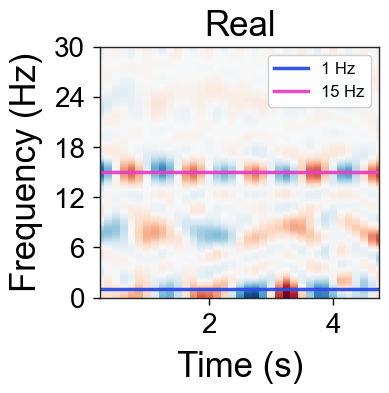

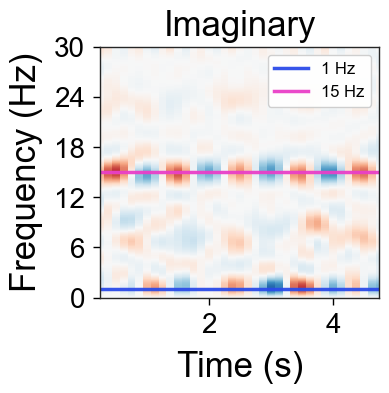

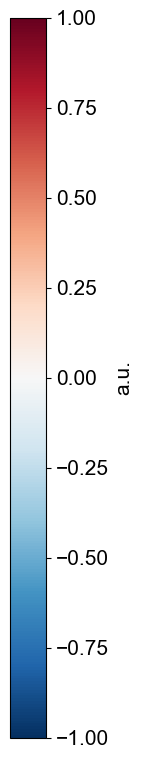

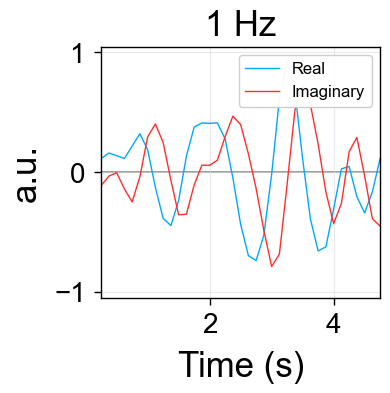

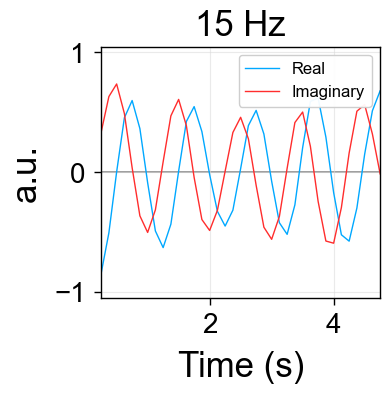

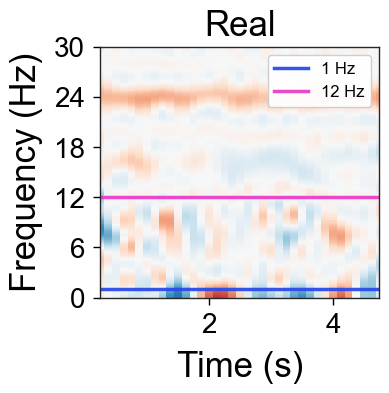

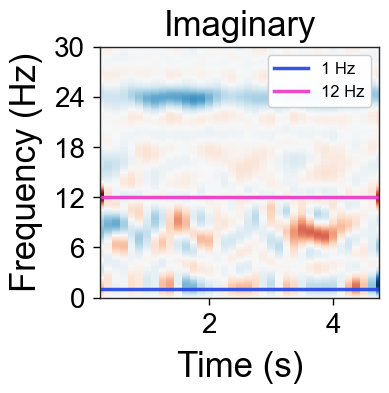

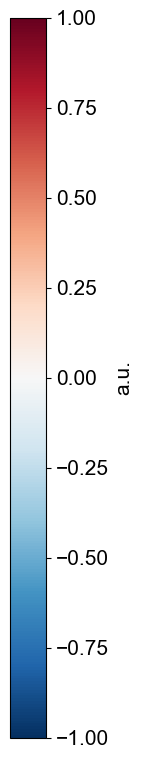

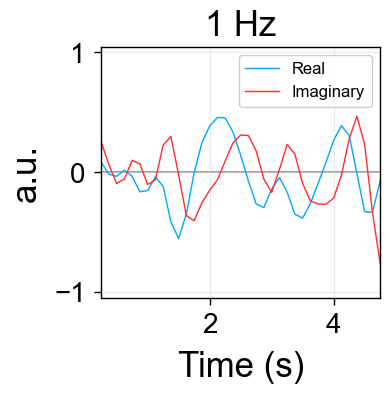

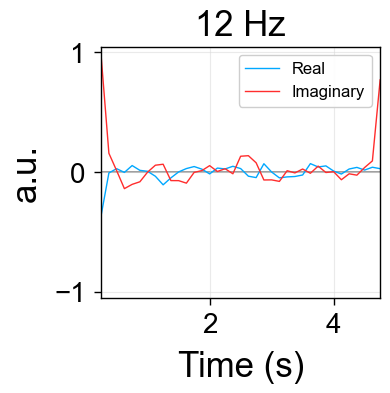

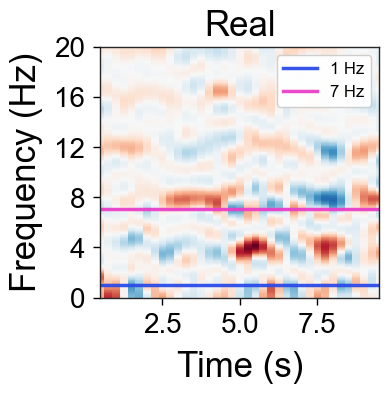

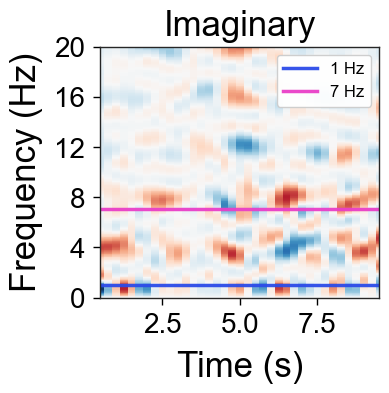

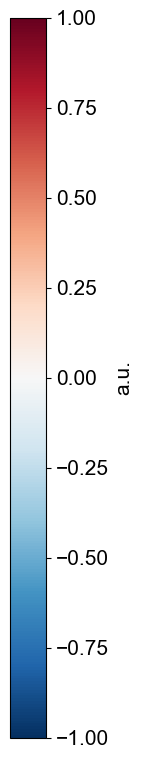

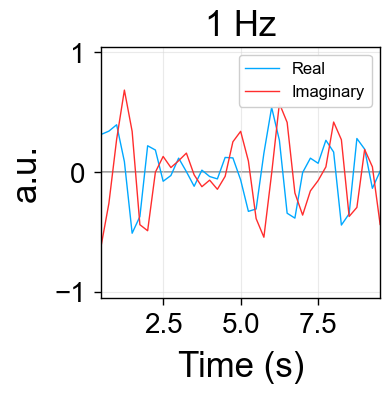

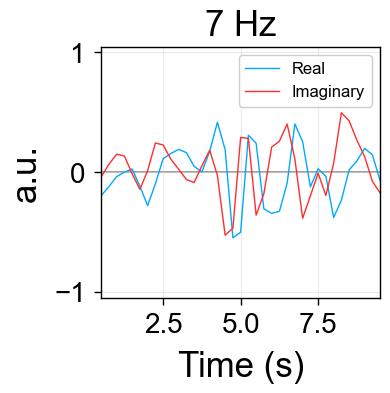

In [8]:
from matplotlib.ticker import MaxNLocator

if 'tf_plot_cache' not in globals() or not tf_plot_cache:
    raise RuntimeError('Run the main experiment cell first to populate tf_plot_cache.')

trace_line_colors = ['#2B4BE8', '#E93FC8', '#8B008B', '#D2691E', '#1E90FF']

def complex_map(data, r_key='real_map', i_key='imag_map'):
    t = np.asarray(data['fit_time'], dtype=np.float32)
    f = np.asarray(data['freq'], dtype=np.float32)
    r0 = np.asarray(data[r_key], dtype=np.float32)
    i0 = np.asarray(data[i_key], dtype=np.float32)
    phase = 2.0 * np.pi * f[:, None] * t[None, :]
    r = np.cos(phase) * r0.T - np.sin(phase) * i0.T
    im = np.sin(phase) * r0.T + np.cos(phase) * i0.T
    if float(tf_display_smooth_sigma) > 0:
        r = scipy.ndimage.gaussian_filter(r, sigma=float(tf_display_smooth_sigma), mode='nearest')
        im = scipy.ndimage.gaussian_filter(im, sigma=float(tf_display_smooth_sigma), mode='nearest')
    scale = max(float(np.nanmax(np.abs(r))), float(np.nanmax(np.abs(im))), 1e-12)
    return r / scale, im / scale

def tf_dir(ds):
    return fig_dir / str(ds).replace(' ', '_').replace('/', '_') / 'tf'

def finish_complex_panel(fig, path):
    path.parent.mkdir(parents=True, exist_ok=True)
    fig.savefig(path, bbox_inches='tight', pad_inches=0.02, dpi=300)
    plt.show()
    plt.close(fig)

def save_complex_map_panel(path, t, f, image, norm, title, spec, slice_freqs=()):
    if not save_tf_figures:
        return
    fig, ax = plt.subplots(figsize=tf_panel_figsize)
    ax.pcolormesh(t, f, image, shading='auto', cmap='RdBu_r', norm=norm, rasterized=True)
    for idx, value in enumerate(slice_freqs):
        color = trace_line_colors[idx % len(trace_line_colors)]
        ax.axhline(value, color=color, linewidth=2.5, alpha=0.95, label=f'{value:.0f} Hz')
    style_tf_ax(ax, title, spec['time_label'], spec['freq_max'], y_label=True, show_y_ticks=True)
    ax.set_xlim(float(t[0]), float(t[-1]))
    ax.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    ax.set_box_aspect(0.9)
    style_legend(ax.legend(loc='upper right', fontsize=12, **LEGEND_FRAME))
    finish_complex_panel(fig, path)

def save_complex_trace_panel(path, t, real_trace, imag_trace, freq_value, spec, colors):
    if not save_tf_figures:
        return
    fig, ax = plt.subplots(figsize=tf_panel_figsize)
    ax.plot(t, real_trace, color=colors['Real'], linewidth=1.0, label='Real')
    ax.plot(t, imag_trace, color=colors['Imaginary'], linewidth=1.0, label='Imaginary')
    ax.axhline(0.0, color='#8C8C8C', linewidth=1.2, zorder=0)
    ax.set_title(f'{freq_value:.0f} Hz', fontsize=tf_font['title'], fontweight='normal', pad=8, color=('green' if abs(float(freq_value) - 1.0) < 1e-6 else 'black'))
    ax.set_xlabel('Time (s)', fontsize=tf_font['label'], fontweight='normal', labelpad=8)
    ax.set_ylabel('a.u.', fontsize=tf_font['label'], fontweight='normal', labelpad=8)
    ax.set_xlim(float(t[0]), float(t[-1]))
    ax.set_ylim(-1.05, 1.05)
    ax.set_box_aspect(0.9)
    ax.grid(True, color='#D9D9D9', linewidth=0.8, alpha=0.55)
    for spine in ax.spines.values():
        spine.set_visible(True)
        spine.set_linewidth(1.0)
    ax.tick_params(axis='both', which='major', direction='out', length=5, width=1.0, labelsize=tf_font['tick'], pad=6)
    for tick_label in [*ax.get_xticklabels(), *ax.get_yticklabels()]:
        tick_label.set_fontweight('normal')
    style_legend(ax.legend(loc='upper right', fontsize=12, **LEGEND_FRAME))
    finish_complex_panel(fig, path)

for ds, data in tf_plot_cache.items():
    if 'real_map' not in data or 'imag_map' not in data:
        print(f"skip OTNSE real/imag TF for {ds}: OTNSE was not selected in tf_methods.")
        continue
    first_keys = {'first_repeat_real_map', 'first_repeat_imag_map'}
    if first_keys.issubset(data):
        t = np.asarray(data['fit_time'], dtype=np.float32)
        f = np.asarray(data['freq'], dtype=np.float32)
        spec = data['spec']
        map_r, map_im = complex_map(data)
        trace_r, trace_im = complex_map(data, 'first_repeat_real_map', 'first_repeat_imag_map')
        f_sel = get_trace_freqs(ds)
        f_idx = np.abs(f[:, None] - f_sel[None, :]).argmin(axis=0)
        f_use = f[f_idx]
        norm = mcolors.TwoSlopeNorm(vmin=-1.0, vcenter=0.0, vmax=1.0)
        comp_colors = {'Real': trace_colors[0], 'Imaginary': trace_colors[1]}
        panel_dir = tf_dir(ds) / 'panels'
        save_complex_map_panel(panel_dir / f'otnse_real_frequency_slice_tf.{save_format}', t, f, map_r, norm, 'Real', spec, f_use)
        save_complex_map_panel(panel_dir / f'otnse_imag_frequency_slice_tf.{save_format}', t, f, map_im, norm, 'Imaginary', spec, f_use)
        if save_tf_figures:
            fig = plt.figure(figsize=(1.8, 8.0))
            cax = fig.add_axes([0.15, 0.05, 0.20, 0.90])
            scalar_map = plt.cm.ScalarMappable(norm=norm, cmap='RdBu_r')
            scalar_map.set_array([])
            cbar = fig.colorbar(scalar_map, cax=cax)
            cbar.set_label(tf_cbar_label, fontsize=tf_font['cbar_label'], fontweight='normal')
            cbar.ax.tick_params(labelsize=tf_font['cbar_tick'])
            for tick_label in cbar.ax.get_yticklabels():
                tick_label.set_fontweight('normal')
            finish_complex_panel(fig, panel_dir / f'otnse_real_imag_slice_colorbar.{save_format}')
        for value, idx in zip(f_use, f_idx):
            save_complex_trace_panel(panel_dir / f'otnse_real_imag_slice_{value:.0f}hz.{save_format}', t, trace_r[idx], trace_im[idx], value, spec, comp_colors)
    else:
        print(f"skip OTNSE complex frequency slices for {ds}: rerun the main experiment cell to cache repeat 1.")


ssvep_sub02_15hz OTNSE PSD traces: requested [1.0, 15.0] Hz, using [0.9765625, 15.0146484375] Hz


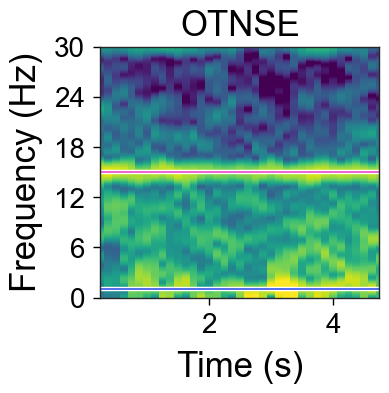

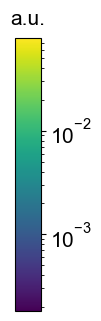

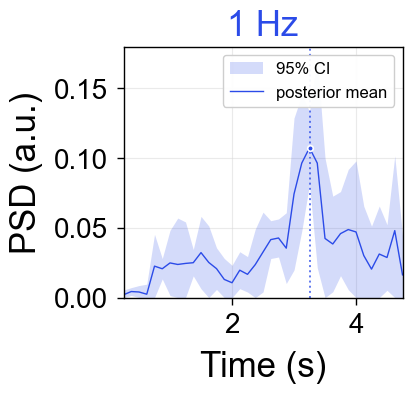

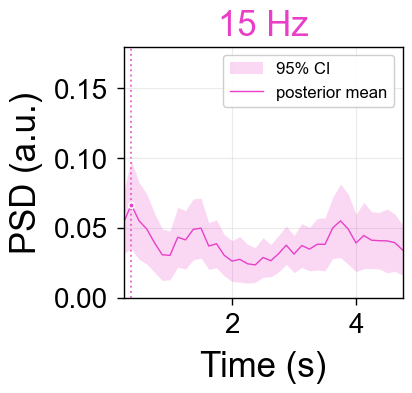

ssvep_sub02_12hz OTNSE PSD traces: requested [1.0, 12.0] Hz, using [0.9765625, 11.962890625] Hz


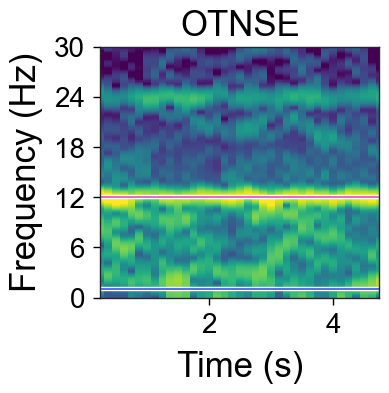

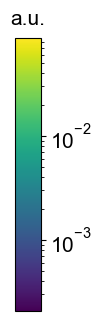

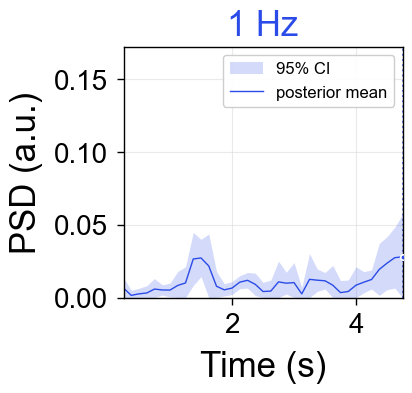

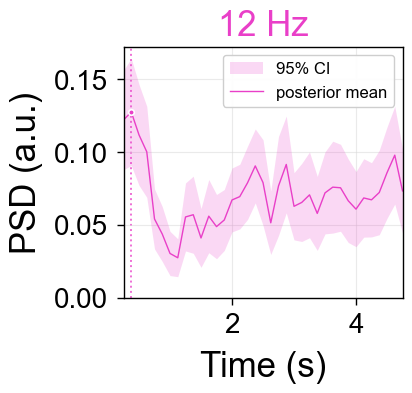

eegmat OTNSE PSD traces: requested [1.0, 7.0] Hz, using [0.9765625, 7.01904296875] Hz


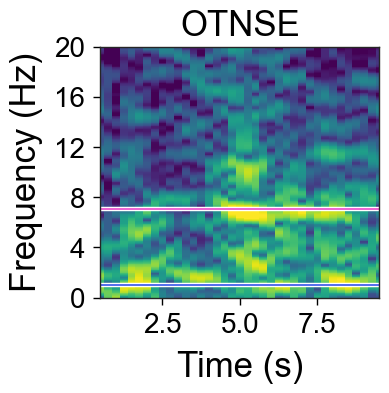

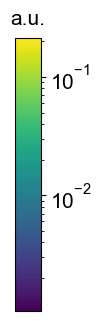

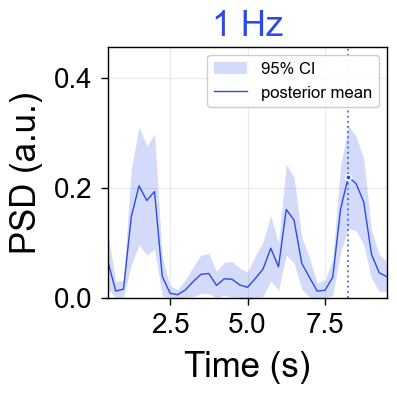

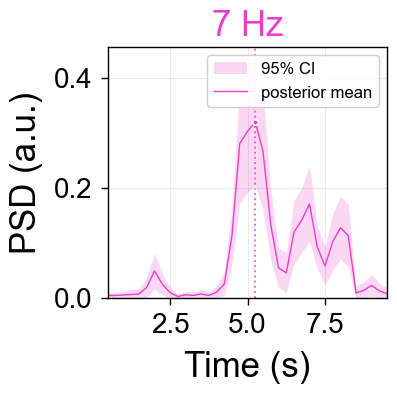

In [9]:
from matplotlib.ticker import MaxNLocator
if 'tf_plot_cache' not in globals() or not tf_plot_cache:
    raise RuntimeError('Run the main experiment cell first to populate tf_plot_cache.')
# Trace colors, ordered like get_trace_freqs(ds) (first color = first frequency).
# Edit here and rerun only this cell.
psd_trace_colors = ['#2B4BE8', '#E93FC8']

for ds, plot_data in tf_plot_cache.items():
    target_freqs = get_trace_freqs(ds)
    required_keys = {'otnse_mean_psd', 'otnse_mean_psd_std'}
    if not required_keys.issubset(plot_data):
        print(f"skip OTNSE PSD traces for {ds}: OTNSE was not selected or no repeat succeeded.")
        continue
    fit_time = np.asarray(plot_data['fit_time'], dtype=np.float32)
    freq = np.asarray(plot_data['freq'], dtype=np.float32)
    mean_psd = np.asarray(plot_data['otnse_mean_psd'], dtype=np.float32)
    std_psd = np.asarray(plot_data['otnse_mean_psd_std'], dtype=np.float32)
    spec = plot_data['spec']
    expected_shape = (len(fit_time), len(freq))
    if mean_psd.shape != expected_shape or std_psd.shape != expected_shape:
        raise ValueError(f"OTNSE PSD shape mismatch for {ds}: expected {expected_shape}")
    freq_idx = np.abs(freq[:, None] - target_freqs[None, :]).argmin(axis=0)
    actual_freqs = freq[freq_idx]
    print(f"{ds} OTNSE PSD traces: requested {target_freqs.tolist()} Hz, using {actual_freqs.tolist()} Hz")
    positive_psd = mean_psd[np.isfinite(mean_psd) & (mean_psd > 0)]
    if positive_psd.size == 0:
        raise ValueError(f'OTNSE PSD for {ds} contains no positive finite values.')
    psd_vmin, psd_vmax = np.quantile(positive_psd, [0.02, 0.995])
    psd_vmax = max(float(psd_vmax), float(psd_vmin) * 1.01)
    panel_dir = tf_dir(ds) / 'panels'

    # posterior PSD map panel
    fig, map_ax = plt.subplots(figsize=(3.6, 3.6))
    map_ax.pcolormesh(
        fit_time,
        freq,
        np.clip(mean_psd.T, psd_vmin, None),
        shading='auto',
        cmap='viridis',
        norm=mcolors.LogNorm(vmin=psd_vmin, vmax=psd_vmax),
        rasterized=True,
    )
    for color, actual_freq in zip(psd_trace_colors, actual_freqs):
        draw_tf_trace_line(map_ax, actual_freq, color, linewidth=1.2, alpha=0.95)
    style_tf_ax(
        map_ax,
        tf_method_labels.get('OTNSE', 'OTNSE'),
        spec['time_label'],
        spec['freq_max'],
    )
    map_ax.set_box_aspect(0.9)
    map_ax.set_xlim(float(fit_time[0]), float(fit_time[-1]))
    map_ax.yaxis.set_major_locator(MaxNLocator(nbins=5, integer=True))
    map_ax.set_axisbelow(True)
    if save_tf_figures:
        fig.savefig(panel_dir / f'otnse_psd_tf.{save_format}', bbox_inches='tight', pad_inches=0.02, dpi=300)
    plt.show()
    plt.close(fig)

    # colorbar panel
    fig = plt.figure(figsize=(1.0, 3.5))
    cax = fig.add_axes([0.12, 0.08, 0.26, 0.78])
    scalar_map = plt.cm.ScalarMappable(
        norm=mcolors.LogNorm(vmin=psd_vmin, vmax=psd_vmax), cmap='viridis'
    )
    scalar_map.set_array([])
    colorbar = fig.colorbar(scalar_map, cax=cax)
    colorbar.ax.set_title(tf_cbar_label, fontsize=tf_font['cbar_label'], fontweight='normal', pad=10)
    colorbar.ax.tick_params(labelsize=tf_font['cbar_tick'])
    for tick_label in colorbar.ax.get_yticklabels():
        tick_label.set_fontweight('normal')
    if save_tf_figures:
        fig.savefig(panel_dir / f'otnse_psd_colorbar.{save_format}')
    plt.show()
    plt.close(fig)

    # posterior PSD trajectory panels, one per trace frequency
    trace_ymax = max(
        float(np.nanmax(mean_psd[:, idx] + 2.0 * np.clip(std_psd[:, idx], 0.0, None)))
        for idx in freq_idx
    )
    trace_ymax = max(trace_ymax * 1.05, np.finfo(np.float32).eps)
    for color, actual_freq, idx in zip(psd_trace_colors, actual_freqs, freq_idx):
        fig, ax = plt.subplots(figsize=tf_panel_figsize)
        posterior_mean = mean_psd[:, idx]
        interval = 2.0 * np.clip(std_psd[:, idx], 0.0, None)
        lower = np.clip(posterior_mean - interval, 0.0, None)
        upper = posterior_mean + interval
        peak_idx = int(np.nanargmax(posterior_mean))
        ax.fill_between(
            fit_time,
            lower,
            upper,
            color=color,
            alpha=0.20,
            linewidth=0,
            label='95% CI',
            zorder=1,
        )
        ax.plot(
            fit_time,
            posterior_mean,
            color=color,
            linewidth=1.0,
            label='posterior mean',
            zorder=2,
        )
        ax.scatter(
            fit_time[peak_idx],
            posterior_mean[peak_idx],
            color=color,
            edgecolor='white',
            linewidth=1.2,
            s=16,
            zorder=3,
        )
        ax.axvline(
            fit_time[peak_idx],
            color=color,
            linestyle=':',
            linewidth=1.4,
            alpha=0.75,
            zorder=0,
        )
        ax.set_title(f'{actual_freq:.0f} Hz', fontsize=tf_font['title'], fontweight='normal', pad=8, color=color)
        ax.set_xlabel(spec['time_label'], fontsize=tf_font['label'], fontweight='normal', labelpad=8)
        ax.set_ylabel('PSD (a.u.)', fontsize=tf_font['label'], fontweight='normal', labelpad=8)
        ax.set_xlim(float(fit_time[0]), float(fit_time[-1]))
        ax.set_ylim(0.0, trace_ymax)
        ax.set_box_aspect(0.9)
        ax.ticklabel_format(axis='y', style='plain')
        ax.grid(True, color='#D9D9D9', linewidth=0.8, alpha=0.55)
        for spine in ax.spines.values():
            spine.set_visible(True)
            spine.set_linewidth(1.0)
        ax.set_axisbelow(True)
        ax.tick_params(axis='both', which='major', direction='out', length=5, width=1.0, labelsize=tf_font['tick'], pad=6)
        for tick_label in [*ax.get_xticklabels(), *ax.get_yticklabels()]:
            tick_label.set_fontweight('normal')
        style_legend(ax.legend(loc='upper right', fontsize=12, **LEGEND_FRAME))
        if save_tf_figures:
            fig.savefig(panel_dir / f'otnse_psd_trace_{actual_freq:.0f}hz.{save_format}', bbox_inches='tight', pad_inches=0.02, dpi=300)
        plt.show()
        plt.close(fig)


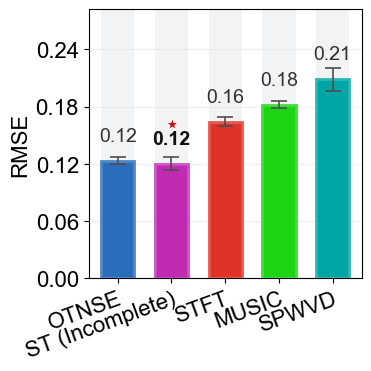

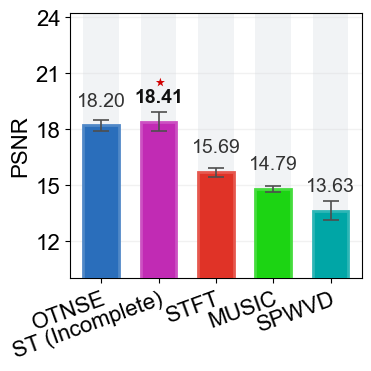

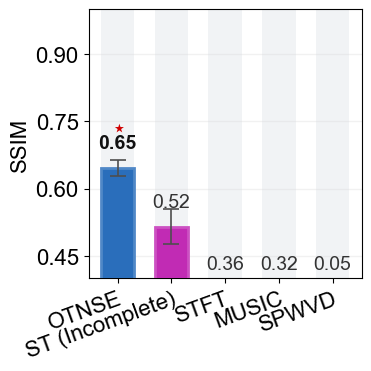

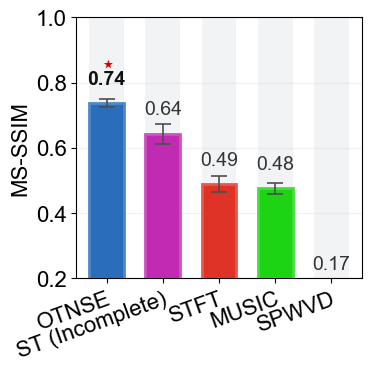

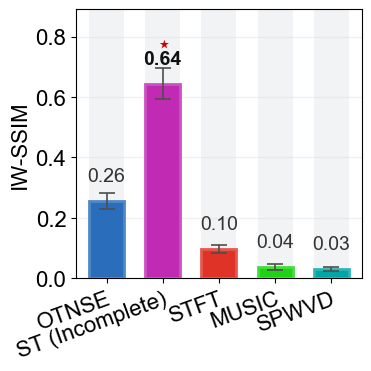

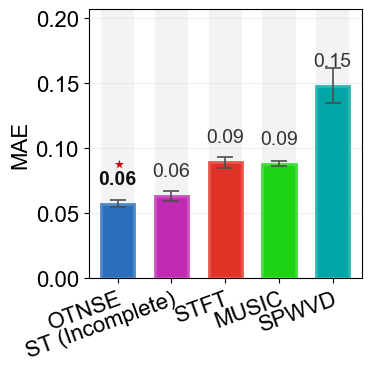

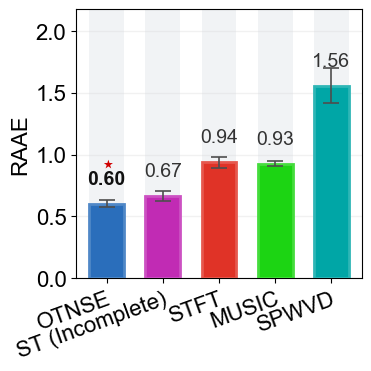

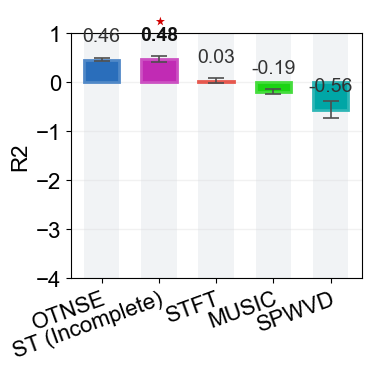

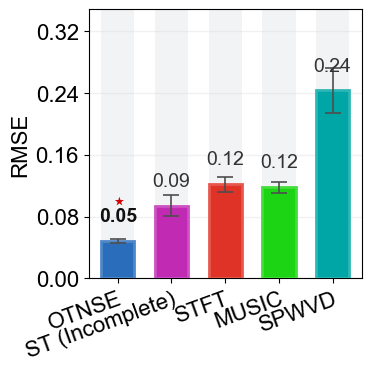

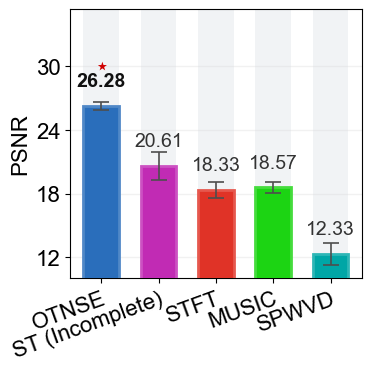

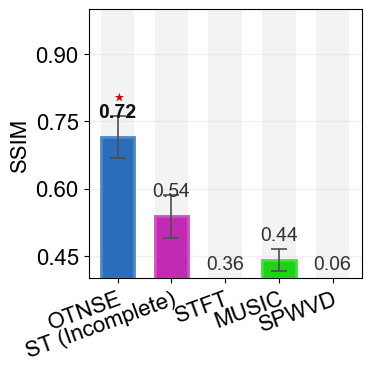

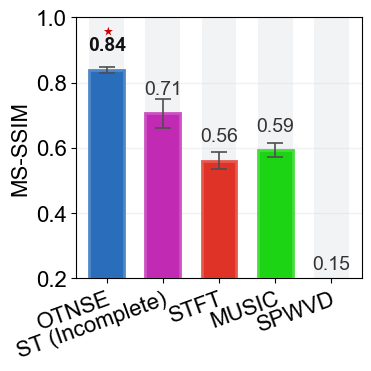

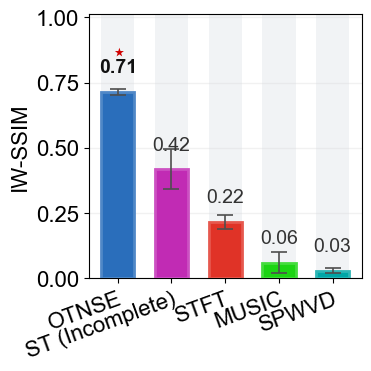

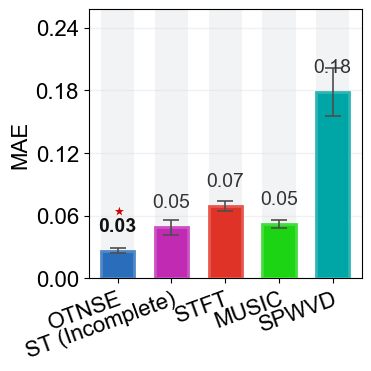

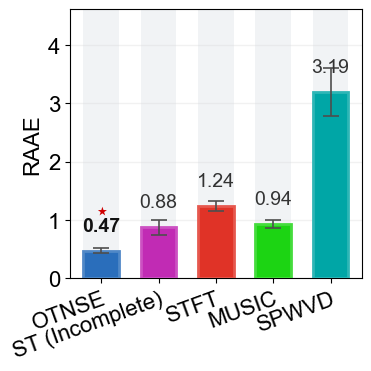

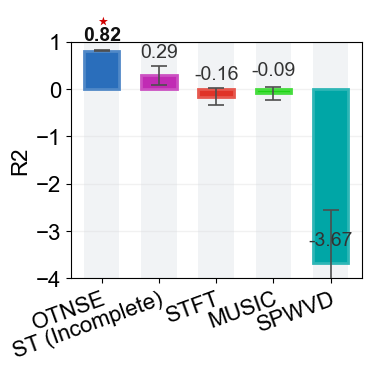

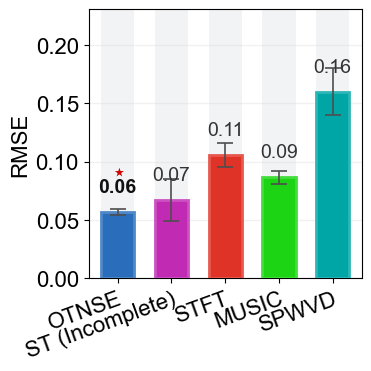

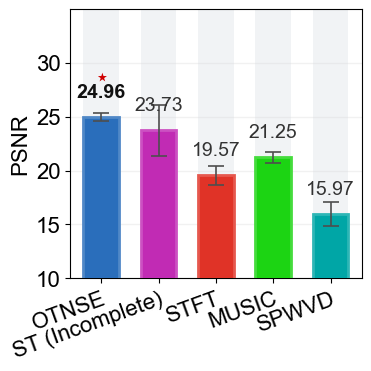

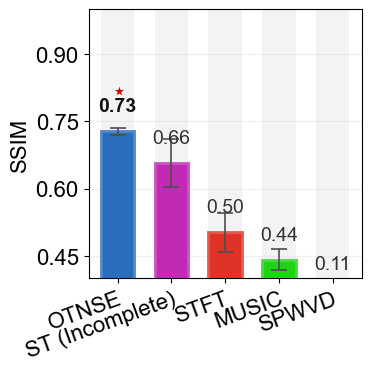

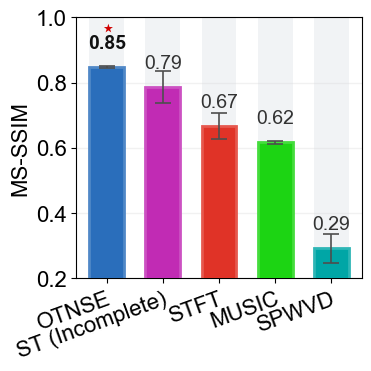

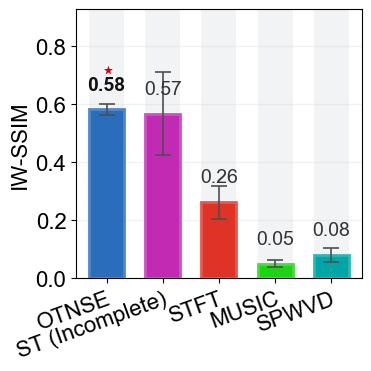

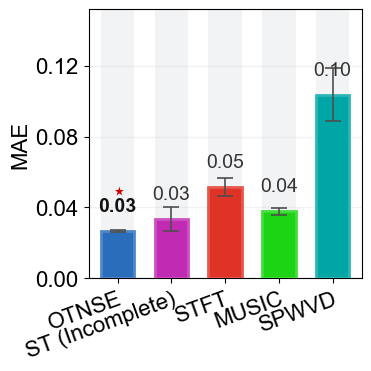

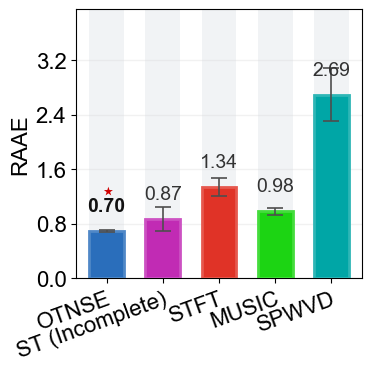

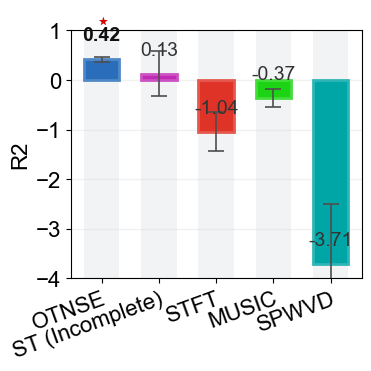

In [15]:
# Bar-chart settings are self-contained in this cell (independent of cell 1).
metric_bar_palette = {
    'OTNSE': '#2a6ebb',
    'OTNSE Uniform': '#00a6d6',
    'ST (Incomplete)': '#c12bb4',  # inherits Multitaper's purple
    'YW': '#f0ab00',
    'STFT': '#e03327',
    'MUSIC': '#1cd413',
    'Multitaper': '#c12bb4',
    'SPWVD': '#00a6a6',
    'Reassigned Spectrogram': '#6f8f00',
}
metric_bar_order = [
    'OTNSE', 'ST (Incomplete)', 'STFT', 'MUSIC', 'SPWVD',  # Multitaper not plotted
]
metric_bar_metrics = [
    'RMSE', 'PSNR', 'SSIM', 'MS-SSIM', 'IW-SSIM','MAE','RAAE','R2'
]
metric_bar_font = {'label': 16, 'tick': 16, 'annotation': 12}


metric_bar_dir = fig_dir
if save_tf_figures:
    metric_bar_dir.mkdir(parents=True, exist_ok=True)

for ds in method_mean_table['Dataset'].drop_duplicates():
    ds_mean = method_mean_table[method_mean_table['Dataset'] == ds].set_index('Method')
    ds_std = method_std_table[method_std_table['Dataset'] == ds].set_index('Method')
    methods = [m for m in metric_bar_order if m in ds_mean.index]
    if not methods:
        continue

    x = np.arange(len(methods))
    bar_colors = [metric_bar_palette.get(m, '#808080') for m in methods]
    metric_column_lookup = {str(col).casefold(): col for col in ds_mean.columns}
    for metric in metric_bar_metrics:
        metric_col = metric_column_lookup.get(str(metric).casefold())
        if metric_col is None:
            print(f"skip metric {metric!r} for {ds}: not found in method_mean_table")
            continue
        values = ds_mean.loc[methods, metric_col].to_numpy(dtype=float)
        errors = ds_std.loc[methods, metric_col].fillna(0.0).to_numpy(dtype=float)
        finite_values = values[np.isfinite(values)]
        finite_errors = errors[np.isfinite(errors)]
        max_error = float(np.max(finite_errors)) if finite_errors.size else 0.0
        ymax = float(np.max(finite_values)) + max_error if finite_values.size else 1.0
        ylim = ymax * 1.28 if ymax > 0 else 1.0
        if metric_col.casefold() == 'r2':
            # R^2 can dive far below 0; a fixed window keeps the panel readable.
            ylim_bottom, ylim_top = -4.0, 1.0
        elif metric_col.casefold() == 'ssim':
            ylim_bottom, ylim_top = 0.4, 1.0
        elif metric_col.casefold() == 'ms-ssim':
            ylim_bottom, ylim_top = 0.2, 1.0
        elif metric_col.casefold() == 'psnr':
            ylim_bottom, ylim_top = 10.0, ylim  # fixed floor, adaptive top
        else:
            ylim_bottom, ylim_top = 0.0, ylim
        lower_is_better = metric_col in LOWER_IS_BETTER_METRICS
        if finite_values.size:
            best_value = float(np.min(finite_values) if lower_is_better else np.max(finite_values))
        else:
            best_value = np.nan
        metric_direction = 'lower is better' if lower_is_better else 'higher is better'

        fig, ax = plt.subplots(figsize=(3.6, 3.6), constrained_layout=True)
        ax.set_facecolor('#FFFFFF')
        ax.bar(
            x,
            np.full(len(methods), ylim_top - ylim_bottom),
            bottom=ylim_bottom,
            color='#F1F3F5',
            edgecolor='none',
            width=0.62,
            zorder=0,
        )
        bars = ax.bar(
            x,
            values,
            yerr=errors,
            color=bar_colors,
            edgecolor='none',
            width=0.62,
            zorder=3,
            error_kw={'elinewidth': 1.2, 'capthick': 1.2, 'capsize': 6, 'ecolor': "#4E4E4E"},
        )
        for method_name, fill_color, bar in zip(methods, bar_colors, bars):
            edge_color = mcolors.to_hex(0.82 * np.asarray(mcolors.to_rgb(fill_color)) + 0.18)
            bar.set_edgecolor(edge_color)
            bar.set_linewidth(2)

        ax.set_xticks(x)
        ax.set_xticklabels(methods, rotation=20, ha='right', rotation_mode='anchor')
        for label in ax.get_xticklabels():
            label.set_x(label.get_position()[0] + 0.03)
        ax.set_ylim(ylim_bottom, ylim_top)
        ax.yaxis.set_major_locator(plt.MaxNLocator(nbins=5))
        ax.set_ylabel(f'{metric_col}', fontsize=metric_bar_font['label'])
        ax.grid(True, axis='y', color="#D9D9D9DD", linewidth=1.0, alpha=0.35)
        ax.set_axisbelow(True)
        ax.tick_params(axis='both', labelsize=metric_bar_font['tick'])
        # for spine in ('top', 'right'):
        #     ax.spines[spine].set_visible(False)
        # for spine in ('left', 'bottom'):
        #     ax.spines[spine].set_color('#BDBDBD')
        # ax.spines[spine].set_linewidth(1.5)

        label_pad = 0.018 * (ylim_top - ylim_bottom)
        for x_pos, value in zip(x, values):
            if not np.isfinite(value):
                continue
            is_best = np.isclose(value, best_value, equal_nan=False)
            text_y = value + label_pad + 0.04 * (ylim_top - ylim_bottom)
            text_y = min(text_y, ylim_top - 0.01 * (ylim_top - ylim_bottom))
            text_y = max(text_y, ylim_bottom + 0.02 * (ylim_top - ylim_bottom))
            ax.text(
                x_pos,
                text_y,
                f'{value:.2f}',
                va='bottom',
                ha='center',
                fontsize=metric_bar_font['annotation']+2,
                fontweight='bold' if is_best else 'normal',
                color='#111111' if is_best else '#333333',
                zorder=5,
            )
            if is_best:
                ax.text(
                    x_pos,
                    text_y + 0.05 * (ylim_top - ylim_bottom),
                    r'$\star$',
                    va='bottom',
                    ha='center',
                    fontsize=metric_bar_font['annotation']+5,
                    fontweight='bold',
                    color='#D00000',
                    zorder=6,
                )

        if save_tf_figures:
            dataset_safe = str(ds).replace(' ', '_').replace('/', '_')
            metric_safe = ''.join(ch.lower() if ch.isalnum() else '_' for ch in metric_col)
            metric_safe = '_'.join(part for part in metric_safe.split('_') if part)
            metric_path = metric_bar_dir / dataset_safe / f'{metric_safe}.{save_format}'
            metric_path.parent.mkdir(parents=True, exist_ok=True)
            fig.savefig(metric_path, bbox_inches='tight')
        plt.show()

In [12]:
# Export standalone panels for Nature figure assembly.
nature_panel_format = 'pdf'

if 'tf_plot_cache' not in globals() or not tf_plot_cache:
    raise RuntimeError('Run the main experiment cell first to populate tf_plot_cache.')


for ds, plot_data in tf_plot_cache.items():
    dataset_safe = nature_safe_name(ds)
    panel_dir = fig_dir / dataset_safe / 'nature_panels'
    fit_time = np.asarray(plot_data['fit_time'], dtype=np.float32)
    freq = np.asarray(plot_data['freq'], dtype=np.float32)
    spec = plot_data['spec']
    time = np.asarray(plot_data['time'], dtype=np.float32)
    signal = np.asarray(plot_data['signal'], dtype=np.float32)
    display_maps = {
        name: prepare_tf_display_map(tf_map)
        for name, tf_map in plot_data['psd_tf_maps'].items()
    }

    fig, ax = plt.subplots(figsize=(7.2, 4.8))
    ax.plot(time, signal, color='blue', linewidth=2.2)
    ax.set_xlabel(spec['time_label'], fontsize=psd_trace_tf_font['label'])
    ax.set_ylabel(spec.get('signal_label', 'Signal'), fontsize=psd_trace_tf_font['label'])
    ax.set_xlim(float(time[0]), float(time[-1]))
    ax.set_box_aspect(0.32)
    ax.tick_params(axis='both', labelsize=psd_trace_tf_font['tick'])
    ax.grid(alpha=0.25, linewidth=0.8)
    finish_nature_panel(fig, panel_dir / f'signal.{nature_panel_format}')

    display_norm = mcolors.Normalize(vmin=0.0, vmax=1.0)
    for method_name in tf_psd_plot_methods:
        if method_name not in display_maps:
            continue
        fig, ax = plt.subplots(figsize=tf_panel_figsize)
        ax.pcolormesh(
            fit_time,
            freq,
            display_maps[method_name].T,
            shading='auto',
            cmap=cmap,
            norm=display_norm,
            rasterized=True,
        )
        overlay_synthetic_true_freq_tracks(
            ax,
            spec,
            time,
            fit_time=fit_time,
            show_legend=False,
        )
        style_tf_ax(
            ax,
            tf_method_labels.get(method_name, method_name),
            spec['time_label'],
            spec['freq_max'],
            y_label=True,
            show_y_ticks=True,
        )
        ax.set_box_aspect(0.9)
        finish_nature_panel(
            fig,
            panel_dir / f'tf_{nature_safe_name(method_name)}.{nature_panel_format}',
        )

    save_nature_colorbar(
        panel_dir / f'tf_colorbar.{nature_panel_format}',
        display_norm,
        tf_cbar_label,
        font=psd_trace_tf_font,
    )

    required_psd_keys = {'otnse_mean_psd', 'otnse_mean_psd_std'}
    if required_psd_keys.issubset(plot_data) and 'psd_trace_freqs_hz' in globals():
        target_freqs = np.asarray(psd_trace_freqs_hz, dtype=np.float64).reshape(-1)
        mean_psd = np.asarray(plot_data['otnse_mean_psd'], dtype=np.float32)
        std_psd = np.asarray(plot_data['otnse_mean_psd_std'], dtype=np.float32)
        freq_idx = np.abs(freq[:, None] - target_freqs[None, :]).argmin(axis=0)
        for actual_freq, idx in zip(freq[freq_idx], freq_idx):
            posterior_mean = mean_psd[:, idx]
            interval = 2.0 * np.clip(std_psd[:, idx], 0.0, None)
            lower = np.clip(posterior_mean - interval, 0.0, None)
            upper = posterior_mean + interval
            fig, ax = plt.subplots(figsize=(7.2, 4.8))
            ax.fill_between(
                fit_time,
                lower,
                upper,
                color='green',
                alpha=0.18,
                linewidth=0,
                label='95% CI',
            )
            ax.plot(
                fit_time,
                posterior_mean,
                color='green',
                linewidth=1.0,
                label='posterior mean',
            )
            ax.set_xlabel(spec['time_label'], fontsize=psd_trace_tf_font['label'])
            ax.set_ylabel('PSD', fontsize=psd_trace_tf_font['label'])
            ax.set_xlim(float(fit_time[0]), float(fit_time[-1]))
            ax.ticklabel_format(axis='y', style='sci', scilimits=(0, 0))
            ax.grid(True, color='#D9D9D9', linewidth=1.0, alpha=0.45)
            ax.tick_params(axis='both', labelsize=psd_trace_tf_font['tick'])
            style_legend(ax.legend(loc='upper right', fontsize=psd_trace_tf_font['tick'], **LEGEND_FRAME))
            freq_safe = nature_safe_name(f'{actual_freq:.3g}_hz')
            finish_nature_panel(
                fig,
                panel_dir / f'otnse_psd_trace_{freq_safe}.{nature_panel_format}',
            )

    print(f'Saved standalone Nature panels: {panel_dir}')


Saved standalone Nature panels: C:\Users\ChengyeLin.LINOUP-XIAOXIN1\Desktop\Slding_window_BNSE_refactored\figures\tf_main_multiq\ssvep_sub02_15hz\nature_panels
Saved standalone Nature panels: C:\Users\ChengyeLin.LINOUP-XIAOXIN1\Desktop\Slding_window_BNSE_refactored\figures\tf_main_multiq\ssvep_sub02_12hz\nature_panels
Saved standalone Nature panels: C:\Users\ChengyeLin.LINOUP-XIAOXIN1\Desktop\Slding_window_BNSE_refactored\figures\tf_main_multiq\eegmat\nature_panels
